# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# Soporte (S0–S6)

Esta sección agrupa, **fuera de los experimentos**, todo lo que los tres experimentos comparten: los `import`, la semilla única, las funciones de lógica y sus comprobaciones. **No es un experimento**: sus celdas no siguen la regla de tres celdas «predicción → implementación → interpretación», que sí rige para E1, E2 y E3.

## Cómo está organizado

| Celda | Contenido |
|---|---|
| **S1** | Imports del stack fijado, semilla única `SEED`, límite `MAX_CONFIGS`, orden y etiquetas de los modelos |
| **S2** | Datos y particiones: `make_splits`, `split_summary`, `sample_examples` |
| **S3** | Fábricas de modelos: `build_classifier`, `build_regressor` |
| **S4** | Protocolo: `fit_capturing_warnings`, `classification_metrics`, `regression_metrics`, `score_classifier`, `score_regressor`, `train_and_score`, `select_config`, `FrozenModel`/`freeze`, `evaluate_once`, `alpha_sweep`, `pick_best_alpha` |
| **S5** | Análisis: `make_table`, `format_config`, `format_warnings`, `simplicity_score`, `indistinguishable_cls`, `indistinguishable_reg`, `rank_models`, `never_predicted_classes`, `is_degenerate_cls`, `is_degenerate_reg`, `top_abs_errors`, `pick_two_errors`, `result_digest` |
| **S6** | Un `assert` como mínimo por cada función de S2–S5, con datos sintéticos (sin pytest) |

## Reglas que se cumplen en todo el notebook

- Las funciones **devuelven valores**: no imprimen, no muestran tablas y no dibujan. Mostrar y graficar ocurre solo en las celdas de implementación de cada experimento.
- Una **configuración** es una combinación distinta de hiperparámetros (incluidos `max_iter` y `solver`); la semilla no cuenta y se inyecta desde `SEED`.
- **Congelar** es fijar la configuración y el modelo ajustado solo con entrenamiento; no se reentrena con validación y la partición de prueba se evalúa una sola vez por modelo.
- Los avisos de scikit-learn se **capturan y se muestran en tablas**; nunca se silencian.
- Solo cuenta como válida la ejecución completa **desde cero** (*Restart & Run All*).

In [1]:
# [S1] Imports, single seed and protocol constants
import hashlib
import warnings
from typing import NamedTuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.datasets import load_diabetes, load_iris
from sklearn.ensemble import (GradientBoostingClassifier, GradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, mean_absolute_error,
                             r2_score, root_mean_squared_error)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

# Single source of randomness: every random_state and every RNG below receives this value.
SEED = 42

# Maximum number of configurations per model, the initial one included.
# The alpha sweep of Ridge and Lasso is the only declared exception.
MAX_CONFIGS = 4

# Model order is fixed by the statement (classification: block 2, regression: block 3).
CLF_KEYS = ["gaussian_nb", "logistic_regression", "linear_svm", "decision_tree",
            "random_forest", "gradient_boosting", "mlp"]
CLF_LABELS = {
    "gaussian_nb": "Gaussian Naive Bayes",
    "logistic_regression": "Regresión logística",
    "linear_svm": "SVM lineal",
    "decision_tree": "Árbol de decisión",
    "random_forest": "Random Forest",
    "gradient_boosting": "Gradient Boosting",
    "mlp": "MLP",
}
REG_KEYS = ["linear_regression", "ridge", "lasso", "knn", "decision_tree",
            "random_forest", "gradient_boosting", "mlp"]
REG_LABELS = {
    "linear_regression": "Regresión lineal",
    "ridge": "Ridge",
    "lasso": "Lasso",
    "knn": "kNN",
    "decision_tree": "Árbol de regresión",
    "random_forest": "Random Forest",
    "gradient_boosting": "Gradient Boosting",
    "mlp": "MLP",
}
PARTITION_LABELS = {"train": "entrenamiento", "val": "validación", "test": "prueba"}

# Table display options (presentation only).
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)

In [2]:
# [S2] Data and partition logic (returns values; nothing is shown or drawn here)
def make_splits(y, stratify, seed):
    """Return sorted index arrays for a 60/20/20 train/val/test partition (two chained splits)."""
    y = np.asarray(y)
    idx = np.arange(len(y))
    rest, test = train_test_split(idx, test_size=0.20, random_state=seed,
                                  stratify=y if stratify else None)
    train, val = train_test_split(rest, test_size=0.25, random_state=seed,
                                  stratify=y[rest] if stratify else None)
    return {"train": np.sort(train), "val": np.sort(val), "test": np.sort(test)}


def split_summary(y, splits, class_names):
    """Size and per-class counts of each partition, as a DataFrame with Spanish headers."""
    y = np.asarray(y)
    rows = []
    for name in ("train", "val", "test"):
        part = y[splits[name]]
        row = {"Partición": PARTITION_LABELS[name], "Tamaño": int(len(part))}
        for code, label in enumerate(class_names):
            row[label] = int(np.sum(part == code))
        rows.append(row)
    return pd.DataFrame(rows)


def sample_examples(y, n, seed):
    """Pick n distinct indices at random, guaranteeing that every class appears at least once."""
    y = np.asarray(y)
    classes = np.unique(y)
    if n < len(classes):
        raise ValueError("n must be at least the number of classes")
    rng = np.random.default_rng(seed)
    chosen = [int(rng.choice(np.flatnonzero(y == c))) for c in classes]
    remaining = np.setdiff1d(np.arange(len(y)), chosen)
    extra = rng.choice(remaining, size=n - len(chosen), replace=False)
    return np.sort(np.concatenate([np.array(chosen, dtype=int), extra.astype(int)]))

In [3]:
# [S3] Model factories (the seed is injected here and is never part of a config)
def build_classifier(key, config, seed, scaled):
    """Return an unfitted Pipeline; the scaler step exists only when scaled is True."""
    if "random_state" in config:
        raise ValueError("the seed is injected by the factory, not written in the config")
    if key == "gaussian_nb":
        model = GaussianNB(**config)
    elif key == "logistic_regression":
        model = LogisticRegression(**config, random_state=seed)
    elif key == "linear_svm":
        model = LinearSVC(**config, random_state=seed)
    elif key == "decision_tree":
        model = DecisionTreeClassifier(**config, random_state=seed)
    elif key == "random_forest":
        model = RandomForestClassifier(**config, random_state=seed)
    elif key == "gradient_boosting":
        model = GradientBoostingClassifier(**config, random_state=seed)
    elif key == "mlp":
        model = MLPClassifier(**config, random_state=seed)
    else:
        raise ValueError(f"unknown classifier key: {key}")
    steps = [("scaler", StandardScaler())] if scaled else []
    return Pipeline(steps + [("model", model)])


# Regressors that need standardized inputs (distance-based, penalized or gradient-trained).
SCALED_REGRESSORS = ("ridge", "lasso", "knn", "mlp")


def build_regressor(key, config, seed):
    """Return an unfitted regressor; only the MLP wraps the target in a train-fitted scaler."""
    if "random_state" in config:
        raise ValueError("the seed is injected by the factory, not written in the config")
    if key == "linear_regression":
        model = LinearRegression(**config)
    elif key == "ridge":
        model = Ridge(**config, random_state=seed)
    elif key == "lasso":
        model = Lasso(**config, random_state=seed)
    elif key == "knn":
        model = KNeighborsRegressor(**config)
    elif key == "decision_tree":
        model = DecisionTreeRegressor(**config, random_state=seed)
    elif key == "random_forest":
        model = RandomForestRegressor(**config, random_state=seed)
    elif key == "gradient_boosting":
        model = GradientBoostingRegressor(**config, random_state=seed)
    elif key == "mlp":
        model = MLPRegressor(**config, random_state=seed)
    else:
        raise ValueError(f"unknown regressor key: {key}")
    steps = [("scaler", StandardScaler())] if key in SCALED_REGRESSORS else []
    pipe = Pipeline(steps + [("model", model)])
    if key == "mlp":
        # The target is standardized with train statistics and inverted before any metric.
        return TransformedTargetRegressor(regressor=pipe, transformer=StandardScaler())
    return pipe

In [4]:
# [S4] Protocol logic: fit, score, select, freeze, single test evaluation and alpha sweep
def fit_capturing_warnings(est, X, y):
    """Fit est and return (est, warnings). Every warning is kept; none is filtered out."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        est.fit(X, y)
    return est, [{"category": w.category.__name__, "message": str(w.message)} for w in caught]


def classification_metrics(y_true, y_pred):
    """Accuracy, macro F1 and micro F1 of a prediction vector."""
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro")),
        "f1_micro": float(f1_score(y_true, y_pred, average="micro")),
    }


def regression_metrics(y_true, y_pred):
    """MAE, RMSE and R2 of a prediction vector (original target scale)."""
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(root_mean_squared_error(y_true, y_pred)),
        "r2": float(r2_score(y_true, y_pred)),
    }


def score_classifier(est, X_eval, y_eval):
    """Predict with a fitted estimator; return (y_pred, metrics, warnings)."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        y_pred = est.predict(X_eval)
        metrics = classification_metrics(y_eval, y_pred)
    return y_pred, metrics, [{"category": w.category.__name__, "message": str(w.message)}
                             for w in caught]


def score_regressor(est, X_eval, y_eval):
    """Predict with a fitted estimator; return (y_pred, metrics, warnings)."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        y_pred = est.predict(X_eval)
        metrics = regression_metrics(y_eval, y_pred)
    return y_pred, metrics, [{"category": w.category.__name__, "message": str(w.message)}
                             for w in caught]


def train_and_score(est, X_fit, y_fit, X_eval, y_eval, scorer):
    """Fit on the fitting data only, score on the evaluation data, keep all warnings."""
    est, fit_warnings = fit_capturing_warnings(est, X_fit, y_fit)
    y_pred, metrics, eval_warnings = scorer(est, X_eval, y_eval)
    return {"estimator": est, "y_pred": y_pred, **metrics,
            "warnings_fit": fit_warnings, "warnings_eval": eval_warnings}


def select_config(records, primary, support, higher_is_better):
    """Pick the best record: primary metric, then support metric, then the one tried first."""
    sign = 1.0 if higher_is_better else -1.0
    return max(records, key=lambda r: (round(sign * r[primary], 12),
                                       round(sign * r[support], 12),
                                       -r["order"]))


class FrozenModel(NamedTuple):
    """Immutable pair (configuration, estimator fitted on train only)."""
    model: str
    config: dict
    estimator: object
    n_configs: int


def freeze(key, record, n_configs):
    """Freeze a chosen record without refitting: the estimator was fitted on train only."""
    return FrozenModel(model=key, config=dict(record["config"]),
                       estimator=record["estimator"], n_configs=int(n_configs))


def evaluate_once(frozen, X_eval, y_eval, ledger, scorer):
    """Score a frozen model on the held-out partition; fails if it was already evaluated."""
    if frozen.model in ledger:
        raise RuntimeError(f"{frozen.model} was already evaluated on the held-out partition")
    ledger.add(frozen.model)
    y_pred, metrics, caught = scorer(frozen.estimator, X_eval, y_eval)
    return {"y_pred": y_pred, **metrics, "warnings_eval": caught}


def alpha_sweep(key, base_config, alphas, data, seed):
    """One fitted pipeline per alpha (fit on data['X_fit']), scored on fit and eval data."""
    rows = []
    for alpha in alphas:
        config = {**base_config, "alpha": float(alpha)}
        est = build_regressor(key, config, seed)
        est, fit_warnings = fit_capturing_warnings(est, data["X_fit"], data["y_fit"])
        _, m_fit, _ = score_regressor(est, data["X_fit"], data["y_fit"])
        _, m_eval, eval_warnings = score_regressor(est, data["X_eval"], data["y_eval"])
        coef = est.named_steps["model"].coef_
        rows.append({
            "model": key, "alpha": float(alpha), "config": config,
            "l2_norm": float(np.linalg.norm(coef)), "n_zero": int(np.sum(coef == 0.0)),
            "rmse_train": m_fit["rmse"], "rmse_val": m_eval["rmse"], "mae_val": m_eval["mae"],
            "coef": np.array(coef, copy=True),
            "warnings_fit": fit_warnings, "warnings_eval": eval_warnings, "estimator": est,
        })
    return rows


def pick_best_alpha(rows):
    """Lowest validation RMSE; an exact tie goes to the smaller alpha. Flags the grid border."""
    best = min(rows, key=lambda r: (round(r["rmse_val"], 12), r["alpha"]))
    alphas = [r["alpha"] for r in rows]
    return {"alpha": best["alpha"],
            "at_border": best["alpha"] in (min(alphas), max(alphas)),
            "row": best}

In [5]:
# [S5] Analysis logic: comparisons, degenerate results, errors and fingerprints
def make_table(rows, columns):
    """DataFrame with exactly the given columns and a 1-based index (presentation is up to the caller)."""
    table = pd.DataFrame(rows, columns=columns)
    table.index = pd.RangeIndex(1, len(table) + 1)
    return table


def format_config(config):
    """Text with only the hyperparameters explicitly written in the configuration."""
    if not config:
        return "sin hiperparámetros fijados"
    parts = []
    for name, value in config.items():
        shown = float(f"{value:.6g}") if isinstance(value, float) else value
        parts.append(f"{name}={shown}")
    return ", ".join(parts)


def format_warnings(warns):
    """Compact text of captured warnings (category and count), or a dash when there are none."""
    if not warns:
        return "—"
    counts = {}
    for item in warns:
        counts[item["category"]] = counts.get(item["category"], 0) + 1
    return "; ".join(f"{name} ×{count}" for name, count in counts.items())


def simplicity_score(frozen):
    """Explicitly fixed hyperparameters plus configurations tried (lower = simpler to program)."""
    return len(frozen.config) + frozen.n_configs


def indistinguishable_cls(errors, best, tol=1):
    """Models (other than best) with at most tol more test errors than the best one."""
    return [m for m, e in errors.items() if m != best and e - errors[best] <= tol]


def indistinguishable_reg(rmse, best, tol=0.05):
    """Models (other than best) within tol (relative to the best RMSE) of the best RMSE."""
    return [m for m, v in rmse.items()
            if m != best and (v - rmse[best]) / rmse[best] <= tol + 1e-12]


def rank_models(values, higher_is_better):
    """Competition ranking (1 = best); ties share the same position."""
    sign = -1.0 if higher_is_better else 1.0
    keyed = {m: round(sign * float(v), 12) for m, v in values.items()}
    return {m: 1 + sum(1 for other in keyed.values() if other < keyed[m]) for m in keyed}


def never_predicted_classes(y_pred, classes):
    """Classes (in the given order) that the prediction vector never contains."""
    seen = set(np.asarray(y_pred).tolist())
    return [int(c) for c in classes if int(c) not in seen]


def is_degenerate_cls(y_pred, classes):
    """True when the classifier never predicts at least one class."""
    return len(never_predicted_classes(y_pred, classes)) > 0


def is_degenerate_reg(est):
    """True when a linear model has every coefficient exactly zero (a constant predictor)."""
    model = est.named_steps["model"] if hasattr(est, "named_steps") else None
    coef = getattr(model, "coef_", None)
    return coef is not None and bool(np.all(np.asarray(coef) == 0.0))


def top_abs_errors(y_true, y_pred, k=2):
    """Positions of the k largest absolute errors (ties go to the smaller position)."""
    err = np.abs(np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float))
    order = sorted(range(len(err)), key=lambda i: (-err[i], i))
    return np.array(order[:k], dtype=int)


def pick_two_errors(pred_main, pred_extra, y_main, y_extra, model_order, idx_main, idx_extra):
    """Up to two distinct misclassified instances, taken from the main (held-out) partition
    first and completed, if needed, from the extra (validation) partition with a label."""
    chosen = []
    wrong_main = {m: np.asarray(pred_main[m]) != np.asarray(y_main) for m in model_order}
    fails = np.sum([wrong_main[m] for m in model_order], axis=0)
    candidates = sorted((i for i in range(len(y_main)) if fails[i] > 0),
                        key=lambda i: (-int(fails[i]), int(idx_main[i])))
    for i in candidates[:2]:
        first = next(m for m in model_order if wrong_main[m][i])
        chosen.append({"index": int(idx_main[i]), "position": int(i), "partition": "prueba",
                       "model": first, "also_failed": int(fails[i]) - 1, "note": ""})
    if len(chosen) < 2:
        wrong_extra = {m: np.asarray(pred_extra[m]) != np.asarray(y_extra) for m in model_order}
        fails_extra = np.sum([wrong_extra[m] for m in model_order], axis=0)
        by_errors = sorted(model_order,
                           key=lambda m: (-int(wrong_extra[m].sum()), model_order.index(m)))
        seen = {c["index"] for c in chosen}
        for m in by_errors:
            for i in sorted(np.flatnonzero(wrong_extra[m]), key=lambda j: int(idx_extra[j])):
                if len(chosen) >= 2:
                    break
                if int(idx_extra[i]) in seen:
                    continue
                seen.add(int(idx_extra[i]))
                chosen.append({"index": int(idx_extra[i]), "position": int(i),
                               "partition": "validación", "model": m,
                               "also_failed": int(fails_extra[i]) - 1,
                               "note": "posible sesgo optimista: la validación se usó para decidir"})
    return chosen


def result_digest(*arrays):
    """Short SHA-256 of the arrays rounded to 6 decimals (shape included)."""
    digest = hashlib.sha256()
    for array in arrays:
        values = np.asarray(array, dtype=float)
        digest.update(str(values.shape).encode())
        digest.update((np.round(values, 6) + 0.0).tobytes())
    return digest.hexdigest()[:16]

In [6]:
# [S6] Checks of every logic function of S2-S5 (plain asserts, synthetic data only)

# ---- S2: make_splits, split_summary, sample_examples ----
_y3 = np.array([0] * 50 + [1] * 50 + [2] * 50)
_sp = make_splits(_y3, stratify=True, seed=SEED)
assert [len(_sp[k]) for k in ("train", "val", "test")] == [90, 30, 30], "make_splits: sizes must be 90/30/30"
_union = np.concatenate([_sp["train"], _sp["val"], _sp["test"]])
assert sorted(_union.tolist()) == list(range(150)), "make_splits: partitions must be disjoint and complete"
for _part, _per_class in (("train", 30), ("val", 10), ("test", 10)):
    assert np.bincount(_y3[_sp[_part]]).tolist() == [_per_class] * 3, "make_splits: stratification broken"
_sp_again = make_splits(_y3, stratify=True, seed=SEED)
assert all(np.array_equal(_sp[k], _sp_again[k]) for k in _sp), "make_splits: same seed, same indices"
_sp_other = make_splits(_y3, stratify=True, seed=SEED + 1)
assert not np.array_equal(_sp["test"], _sp_other["test"]), "make_splits: another seed must change the split"
_sp_reg = make_splits(np.zeros(442), stratify=False, seed=SEED)
assert [len(_sp_reg[k]) for k in ("train", "val", "test")] == [264, 89, 89], "make_splits: 442 rows -> 264/89/89"

_summary = split_summary(_y3, _sp, ["a", "b", "c"])
assert _summary["Tamaño"].tolist() == [90, 30, 30], "split_summary: sizes"
assert _summary[["a", "b", "c"]].to_numpy().tolist() == [[30, 30, 30], [10, 10, 10], [10, 10, 10]], \
    "split_summary: per-class counts"

_ex = sample_examples(_y3, 5, SEED)
assert len(set(_ex.tolist())) == 5, "sample_examples: indices must be distinct"
assert set(_y3[_ex].tolist()) == {0, 1, 2}, "sample_examples: all classes must appear"
assert np.array_equal(_ex, sample_examples(_y3, 5, SEED)), "sample_examples: must be deterministic"

# ---- S3: build_classifier, build_regressor ----
assert len(CLF_KEYS) == 7 and len(REG_KEYS) == 8, "model lists must have 7 classifiers and 8 regressors"
for _scaled in (True, False):
    for _key in CLF_KEYS:
        _est = build_classifier(_key, {}, SEED, scaled=_scaled)
        _step_names = [name for name, _ in _est.steps]
        assert _step_names == (["scaler", "model"] if _scaled else ["model"]), "build_classifier: scaler step"
        if _scaled:
            assert isinstance(_est.named_steps["scaler"], StandardScaler), "build_classifier: StandardScaler"
        _params = _est.named_steps["model"].get_params()
        assert _params.get("random_state", SEED) == SEED, "build_classifier: random_state must be SEED"
assert isinstance(build_classifier("linear_svm", {}, SEED, True).named_steps["model"], LinearSVC)
assert build_classifier("mlp", {}, SEED, True).named_steps["model"].early_stopping is False, \
    "MLP must not use an internal validation split"
assert build_classifier("gradient_boosting", {}, SEED, True).named_steps["model"].n_iter_no_change is None, \
    "Gradient Boosting must not use an internal validation split"

for _key in REG_KEYS:
    _est = build_regressor(_key, {}, SEED)
    _core = _est.regressor if isinstance(_est, TransformedTargetRegressor) else _est
    assert ("scaler" in _core.named_steps) == (_key in ("ridge", "lasso", "knn", "mlp")), "build_regressor: scaler"
    assert _core.named_steps["model"].get_params().get("random_state", SEED) == SEED, "build_regressor: seed"
assert [isinstance(build_regressor(k, {}, SEED), TransformedTargetRegressor) for k in REG_KEYS] == \
    [k == "mlp" for k in REG_KEYS], "only the MLP wraps the target"
_mlp_core = build_regressor("mlp", {}, SEED).regressor.named_steps["model"]
assert _mlp_core.early_stopping is False, "MLP regressor must not use an internal validation split"
assert build_regressor("gradient_boosting", {}, SEED).named_steps["model"].n_iter_no_change is None

# ---- S4: fit_capturing_warnings, metrics, score_*, train_and_score ----
_rng = np.random.default_rng(SEED)
_Xc = _rng.normal(size=(90, 4))
_yc = np.digitize(_Xc[:, 0] + 0.3 * _Xc[:, 1], [-0.5, 0.5])
_lr, _lr_warnings = fit_capturing_warnings(LogisticRegression(max_iter=1), _Xc, _yc)
assert hasattr(_lr, "coef_"), "fit_capturing_warnings: estimator must come back fitted"
assert any(w["category"] == "ConvergenceWarning" for w in _lr_warnings), "ConvergenceWarning must be captured"

_m = classification_metrics([0, 0, 1, 1, 2, 2], [0, 0, 1, 2, 2, 2])
assert abs(_m["f1_macro"] - (1 + 2 / 3 + 4 / 5) / 3) < 1e-12, "classification_metrics: macro F1"
assert abs(_m["f1_micro"] - 5 / 6) < 1e-12 and abs(_m["accuracy"] - 5 / 6) < 1e-12, "micro F1 equals accuracy"
_r = regression_metrics([1, 2, 3], [1, 2, 5])
assert abs(_r["mae"] - 2 / 3) < 1e-12 and abs(_r["rmse"] - np.sqrt(4 / 3)) < 1e-12 and abs(_r["r2"] + 1) < 1e-12, \
    "regression_metrics: MAE, RMSE and R2 of a known case"

_pred, _met, _score_warnings = score_classifier(_lr, _Xc, _yc)
assert _met == classification_metrics(_yc, _pred) and isinstance(_score_warnings, list), "score_classifier"
_Xr = _rng.normal(size=(60, 3))
_yr = _Xr @ np.array([2.0, -1.0, 0.5]) + 10
_lin, _ = fit_capturing_warnings(build_regressor("linear_regression", {}, SEED), _Xr, _yr)
_pred_r, _met_r, _ = score_regressor(_lin, _Xr, _yr)
assert _met_r == regression_metrics(_yr, _pred_r) and _met_r["r2"] > 0.999, "score_regressor"

_res = train_and_score(build_classifier("gaussian_nb", {}, SEED, True), _Xc, _yc, _Xc, _yc, score_classifier)
assert set(_res) >= {"estimator", "y_pred", "accuracy", "f1_macro", "warnings_fit", "warnings_eval"}, \
    "train_and_score: result keys"

# ---- S4: select_config ----
_recs = [{"order": 0, "f1": 0.9, "acc": 0.8}, {"order": 1, "f1": 0.9, "acc": 0.9}, {"order": 2, "f1": 0.8, "acc": 1.0}]
assert select_config(_recs, "f1", "acc", True)["order"] == 1, "select_config: tie goes to the support metric"
_recs_tie = [{"order": 0, "f1": 0.9, "acc": 0.9}, {"order": 1, "f1": 0.9, "acc": 0.9}]
assert select_config(_recs_tie, "f1", "acc", True)["order"] == 0, "select_config: persistent tie, first tried"
_recs_reg = [{"order": 0, "rmse": 5.0, "mae": 4.0}, {"order": 1, "rmse": 3.0, "mae": 4.5},
             {"order": 2, "rmse": 3.0, "mae": 4.0}]
assert select_config(_recs_reg, "rmse", "mae", False)["order"] == 2, "select_config: lower is better"

# ---- S4: freeze, evaluate_once ----
_nb, _ = fit_capturing_warnings(build_classifier("gaussian_nb", {}, SEED, True), _Xc, _yc)
_frozen = freeze("gaussian_nb", {"order": 0, "config": {"var_smoothing": 1e-9}, "estimator": _nb}, 3)
assert _frozen.model == "gaussian_nb" and _frozen.n_configs == 3 and _frozen.estimator is _nb, "freeze fields"
try:
    _frozen.model = "other"
    raise AssertionError("FrozenModel must be immutable")
except AttributeError:
    pass
_ledger = set()
_first = evaluate_once(_frozen, _Xc, _yc, _ledger, score_classifier)
assert _ledger == {"gaussian_nb"} and np.array_equal(_first["y_pred"], _nb.predict(_Xc)), "evaluate_once"
try:
    evaluate_once(_frozen, _Xc, _yc, _ledger, score_classifier)
    raise AssertionError("a second evaluation of the same model must fail")
except RuntimeError:
    pass

# ---- S4: alpha_sweep, pick_best_alpha ----
_Xa = _rng.normal(size=(120, 5))
_ya = _Xa @ np.array([3.0, -2.0, 0.0, 0.0, 1.0]) + _rng.normal(scale=0.5, size=120)
_data = {"X_fit": _Xa[:80], "y_fit": _ya[:80], "X_eval": _Xa[80:], "y_eval": _ya[80:]}
_ridge_rows = alpha_sweep("ridge", {}, np.logspace(-2, 2, 6), _data, SEED)
_norms = [row["l2_norm"] for row in _ridge_rows]
assert all(_norms[i] >= _norms[i + 1] for i in range(len(_norms) - 1)), "Ridge L2 norm must not grow with alpha"
_Xs = StandardScaler().fit_transform(_data["X_fit"])
_alpha_max = np.max(np.abs(_Xs.T @ (_data["y_fit"] - _data["y_fit"].mean()))) / len(_Xs)
_lasso_rows = alpha_sweep("lasso", {"max_iter": 10000}, [1e-3, _alpha_max * 1.01], _data, SEED)
assert _lasso_rows[-1]["n_zero"] == 5, "Lasso above alpha_max must zero every coefficient"
assert _lasso_rows[0]["n_zero"] < 5, "Lasso with a tiny alpha must keep coefficients"

_grid_rows = [{"alpha": 0.1, "rmse_val": 5.0}, {"alpha": 1.0, "rmse_val": 3.0},
              {"alpha": 10.0, "rmse_val": 3.0}, {"alpha": 100.0, "rmse_val": 9.0}]
_best = pick_best_alpha(_grid_rows)
assert _best["alpha"] == 1.0 and _best["at_border"] is False, "pick_best_alpha: exact tie goes to the smaller alpha"
_border = pick_best_alpha([{"alpha": 0.1, "rmse_val": 1.0}, {"alpha": 1.0, "rmse_val": 2.0}])
assert _border["alpha"] == 0.1 and _border["at_border"] is True, "pick_best_alpha: border must be flagged"

# ---- S5: tables, formatting, simplicity, ranking ----
_tab = make_table([[1, 2], [3, 4]], ["a", "b"])
assert list(_tab.columns) == ["a", "b"] and list(_tab.index) == [1, 2], "make_table: columns and 1-based index"
assert format_config({"C": 1.0, "max_iter": 1000}) == "C=1.0, max_iter=1000", "format_config"
assert format_config({}) == "sin hiperparámetros fijados", "format_config: empty config"
assert format_warnings([]) == "—", "format_warnings: empty"
assert format_warnings([{"category": "ConvergenceWarning", "message": "x"}] * 2) == "ConvergenceWarning ×2"
assert simplicity_score(FrozenModel("m", {"a": 1, "b": 2}, None, 3)) == 5, "simplicity_score"
assert rank_models({"a": 0.9, "b": 0.9, "c": 0.8}, True) == {"a": 1, "b": 1, "c": 3}, "rank_models: ties"
assert rank_models({"a": 2.0, "b": 1.0}, False) == {"a": 2, "b": 1}, "rank_models: lower is better"

# ---- S5: indistinguishable_*, degenerate, top errors ----
assert indistinguishable_cls({"a": 2, "b": 3, "c": 4}, "a") == ["b"], "cls: 1 error apart included, 2 excluded"
assert indistinguishable_cls({"a": 2, "b": 1}, "a") == ["b"], "cls: fewer errors than the best is included"
assert indistinguishable_reg({"a": 100.0, "b": 105.0, "c": 105.01}, "a") == ["b"], "reg: exactly 5% included"
assert never_predicted_classes([0, 0, 1], [0, 1, 2]) == [2], "never_predicted_classes"
assert is_degenerate_cls([0, 0, 1], [0, 1, 2]) and not is_degenerate_cls([0, 1, 2], [0, 1, 2]), "is_degenerate_cls"
_zero, _ = fit_capturing_warnings(build_regressor("lasso", {"alpha": 1e6, "max_iter": 1000}, SEED), _Xa, _ya)
_ridge, _ = fit_capturing_warnings(build_regressor("ridge", {"alpha": 1.0}, SEED), _Xa, _ya)
assert is_degenerate_reg(_zero) and not is_degenerate_reg(_ridge), "is_degenerate_reg"
assert top_abs_errors([0, 0, 0, 0], [1, -3, 3, 0.5], k=2).tolist() == [1, 2], "top_abs_errors: ties, smaller position"

# ---- S5: pick_two_errors (three scenarios plus a validation-only case) ----
_order = ["m1", "m2", "m3"]
_yt = np.array([0, 1, 2, 0, 1, 2])
_it = np.array([10, 11, 12, 13, 14, 15])
_pt = {"m1": np.array([0, 2, 2, 0, 0, 2]), "m2": np.array([0, 2, 2, 0, 1, 2]), "m3": np.array([0, 1, 0, 0, 0, 2])}
_yv = np.array([0, 1, 2, 0])
_iv = np.array([20, 21, 22, 23])
_pv = {"m1": np.array([0, 2, 2, 0]), "m2": np.array([0, 1, 2, 0]), "m3": np.array([0, 2, 2, 1])}
_two = pick_two_errors(_pt, _pv, _yt, _yv, _order, _it, _iv)
assert [e["index"] for e in _two] == [11, 14] and all(e["partition"] == "prueba" for e in _two), \
    "pick_two_errors: test errors ordered by number of failing models"
assert _two[0]["model"] == "m1" and _two[0]["also_failed"] == 1, "pick_two_errors: first failing model and count"
_one_test = {"m1": np.array([0, 1, 2, 0, 1, 2]), "m2": np.array([0, 2, 2, 0, 1, 2]), "m3": _yt.copy()}
_mixed = pick_two_errors(_one_test, _pv, _yt, _yv, _order, _it, _iv)
assert [e["partition"] for e in _mixed] == ["prueba", "validación"], "pick_two_errors: test first, then validation"
assert _mixed[1]["model"] == "m3" and _mixed[1]["index"] == 21, \
    "pick_two_errors: validation error comes from the model with most validation errors"
assert "optimista" in _mixed[1]["note"], "pick_two_errors: optimistic-bias note"
_clean = {m: _yt.copy() for m in _order}
_clean_v = {m: _yv.copy() for m in _order}
assert pick_two_errors(_clean, _clean_v, _yt, _yv, _order, _it, _iv) == [], "pick_two_errors: no errors anywhere"
_val_only = pick_two_errors(_clean, _pv, _yt, _yv, _order, _it, _iv)
assert [e["index"] for e in _val_only] == [21, 23] and {e["model"] for e in _val_only} == {"m3"}, \
    "pick_two_errors: validation-only errors come from the model with most validation errors"

# ---- S5: result_digest ----
_fp = result_digest(np.array([0.5, 1.5]), np.array([[1.0, 2.0]]))
assert _fp == result_digest(np.array([0.5, 1.5]), np.array([[1.0, 2.0]])), "fingerprint: same input"
assert _fp != result_digest(np.array([0.5, 1.6]), np.array([[1.0, 2.0]])), "fingerprint: altered input"
assert _fp == result_digest(np.array([0.5 + 1e-9, 1.5]), np.array([[1.0, 2.0]])), "fingerprint: 6 decimals"

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


## E1.P — Predicción inicial del experimento 1 (antes de cargar los datos)

Registro lo que espero encontrar **antes** de cargar Iris. Este texto no se modifica después de ejecutar la implementación de E1.

1. **Tamaño.** Espero un dataset pequeño: unas **150 instancias** y **4 características** numéricas (medidas de flores en centímetros). La matriz de características debería ser de 150 × 4 y el vector de etiquetas debería tener 150 entradas.
2. **Balance.** Espero **3 clases** con el mismo número de ejemplos, **50 por clase** (un tercio cada una). Es decir, espero un dataset perfectamente balanceado.
3. **Consecuencia para la partición.** Con 150 instancias, una partición 60/20/20 estratificada debería dar 90/30/30 instancias, con 30/10/10 por clase en entrenamiento, validación y prueba. Con solo 10 ejemplos por clase en validación y en prueba, espero que un único ejemplo mal clasificado mueva las métricas de forma visible.

T1.1 — Descripción general del dataset Iris


,Concepto,Valor
1,Qué representa cada instancia,Una flor de iris (una observación)
2,Número de instancias,150
3,Número de características,4
4,Forma de la matriz de características X,"(150, 4)"
5,Forma del vector de etiquetas y,"(150,)"



T1.2 — Características


,Característica (nombre de la librería),Significado
1,sepal length (cm),"longitud del sépalo, en centímetros"
2,sepal width (cm),"ancho del sépalo, en centímetros"
3,petal length (cm),"longitud del pétalo, en centímetros"
4,petal width (cm),"ancho del pétalo, en centímetros"



T1.3 — Clases y número de ejemplos por clase


,Clase,Ejemplos
1,setosa,50
2,versicolor,50
3,virginica,50



T1.4 — Cinco ejemplos elegidos al azar con la semilla única


,Índice,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Clase
1,4,5.0,3.6,1.4,0.2,setosa
2,64,5.6,2.9,3.6,1.3,versicolor
3,65,6.7,3.1,4.4,1.4,versicolor
4,88,5.6,3.0,4.1,1.3,versicolor
5,132,6.4,2.8,5.6,2.2,virginica


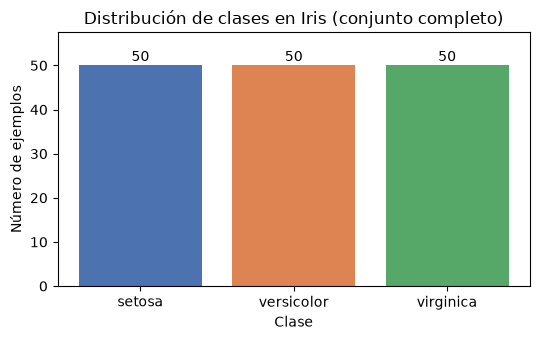


T1.5 — Partición 60/20/20 estratificada (declarada antes de entrenar)


,Partición,Tamaño,setosa,versicolor,virginica
1,entrenamiento,90,30,30,30
2,validación,30,10,10,10
3,prueba,30,10,10,10



Huella de E1 (debe repetirse en cada ejecución desde cero): 689602a2376f3020


In [7]:
# [E1.1] Load Iris with scikit-learn and check the shapes
iris = load_iris()
X_iris, y_iris = iris.data, iris.target
assert X_iris.shape == (150, 4), "Iris feature matrix must be 150 x 4"
assert y_iris.shape == (150,), "Iris label vector must have 150 entries"
feature_names = list(iris.feature_names)
class_names = iris.target_names.tolist()
class_codes = np.unique(y_iris)

# [E1.2] Descriptive tables T1.1-T1.3 (generated from the loaded data)
FEATURE_MEANING = {
    "sepal length (cm)": "longitud del sépalo, en centímetros",
    "sepal width (cm)": "ancho del sépalo, en centímetros",
    "petal length (cm)": "longitud del pétalo, en centímetros",
    "petal width (cm)": "ancho del pétalo, en centímetros",
}
assert list(FEATURE_MEANING) == feature_names, "every feature name must have a Spanish meaning"

t11 = make_table([
    ["Qué representa cada instancia", "Una flor de iris (una observación)"],
    ["Número de instancias", X_iris.shape[0]],
    ["Número de características", X_iris.shape[1]],
    ["Forma de la matriz de características X", str(X_iris.shape)],
    ["Forma del vector de etiquetas y", str(y_iris.shape)],
], ["Concepto", "Valor"])
t12 = make_table([[name, FEATURE_MEANING[name]] for name in feature_names],
                 ["Característica (nombre de la librería)", "Significado"])
t13 = make_table([[name, int(np.sum(y_iris == code))] for code, name in zip(class_codes, class_names)],
                 ["Clase", "Ejemplos"])
print("T1.1 — Descripción general del dataset Iris")
display(t11)
print("\nT1.2 — Características")
display(t12)
print("\nT1.3 — Clases y número de ejemplos por clase")
display(t13)

# [E1.3] Five random examples (single seed), all three classes guaranteed -> T1.4
example_idx = sample_examples(y_iris, 5, SEED)
assert set(y_iris[example_idx].tolist()) == set(class_codes.tolist()), "the 5 examples must include all classes"
t14 = make_table(
    [[int(i)] + X_iris[i].tolist() + [class_names[y_iris[i]]] for i in example_idx],
    ["Índice"] + feature_names + ["Clase"])
print("\nT1.4 — Cinco ejemplos elegidos al azar con la semilla única")
display(t14)

# [E1.4] Class distribution of the complete dataset -> F1.1
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.bar(class_names, t13["Ejemplos"].to_numpy(), color=["#4c72b0", "#dd8452", "#55a868"])
ax.set_title("Distribución de clases en Iris (conjunto completo)")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de ejemplos")
ax.set_ylim(0, t13["Ejemplos"].max() * 1.15)
for pos, count in enumerate(t13["Ejemplos"]):
    ax.text(pos, count + 1, str(count), ha="center")
plt.tight_layout()
plt.show()

# [E1.5] Partition declared once, before any model is trained -> T1.5
splits_iris = make_splits(y_iris, stratify=True, seed=SEED)
assert [len(splits_iris[k]) for k in ("train", "val", "test")] == [90, 30, 30], "sizes must be 90/30/30"
all_idx = np.concatenate([splits_iris["train"], splits_iris["val"], splits_iris["test"]])
assert sorted(all_idx.tolist()) == list(range(150)), "partitions must be disjoint and complete"
summary_iris = split_summary(y_iris, splits_iris, class_names)
t15 = make_table(summary_iris.to_numpy().tolist(), list(summary_iris.columns))
assert list(t15.columns) == ["Partición", "Tamaño"] + class_names, "T1.5 columns"
assert (t15.iloc[1:][class_names].to_numpy() == 10).all(), "validation and test must hold 10 per class"
print("\nT1.5 — Partición 60/20/20 estratificada (declarada antes de entrenar)")
display(t15)

# [E1.6] Reproducibility fingerprint of E1
fingerprint_e1 = result_digest(X_iris[example_idx], example_idx, splits_iris["train"],
                               splits_iris["val"], splits_iris["test"])
print("\nHuella de E1 (debe repetirse en cada ejecución desde cero):", fingerprint_e1)

## E1.I — Interpretación del experimento 1

### ¿Están las clases balanceadas y qué implica para las métricas?

**Sí, están perfectamente balanceadas**: las tres clases (`setosa`, `versicolor`, `virginica`) tienen 50 ejemplos cada una (T1.3 y F1.1). La partición estratificada conserva esa proporción: 30/10/10 ejemplos por clase en entrenamiento, validación y prueba (T1.5).

Qué implica para elegir métricas:

- Sin clase mayoritaria, un clasificador que predijera siempre la misma clase acertaría alrededor de 1/3 de las veces; la **accuracy no queda inflada por el desbalance** y es interpretable.
- Aun así, el tamaño importa más que el balance: con 10 ejemplos por clase en validación y en prueba (30 en total), **un solo ejemplo mal clasificado cambia la accuracy en 1/30 ≈ 0.033**. Las diferencias pequeñas entre modelos serán difíciles de distinguir del azar de la partición.
- Usaré **F1 macro como métrica de decisión** porque promedia las clases por igual y no depende de que una clase domine, y **accuracy como apoyo**. Que ambas coincidan o no en un experimento concreto es algo que se comprobará con resultados (E2), no algo que el balance garantice.

### Contraste con la predicción de E1.P

| Predicción | Resultado | Veredicto |
|---|---|---|
| ~150 instancias y 4 características; X de 150 × 4 e y de 150 entradas | 150 instancias, 4 características, X `(150, 4)` e y `(150,)` (T1.1) | **Confirmada** |
| 3 clases con 50 ejemplos cada una (balanceado) | 50, 50 y 50 (T1.3, F1.1) | **Confirmada** |
| Partición 60/20/20 estratificada: 90/30/30 y 30/10/10 por clase | 90/30/30 y 30/10/10 por clase (T1.5) | **Confirmada** |
| «Un único ejemplo mal clasificado moverá las métricas de forma visible» | Un ejemplo vale 1/30 ≈ 0.033 de accuracy con 30 instancias | **Consistente por construcción**; se comprobará con resultados reales en E2 |

La predicción era sobre un dataset muy conocido, así que acertar no sorprende: lo que aporta el ejercicio es dejar explícito, antes de modelar, el tamaño de la muestra con el que se tomarán las decisiones.

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

## E2.P — Predicciones iniciales del experimento 2 (antes de implementar)

Registro mis predicciones **antes** de implementar. Este texto no se modifica después de ejecutar la implementación de E2.

### 1. Sensibilidad a la escala de las características

Espero que sean **sensibles a la escala** los modelos que optimizan una función de pérdida con gradientes o penalizan la magnitud de los pesos: la **regresión logística**, la **SVM lineal** y el **MLP**. Espero que sean **poco sensibles** el **árbol de decisión**, el **Random Forest** y el **Gradient Boosting** (sus particiones dependen solo del orden de los valores de cada característica) y **Gaussian Naive Bayes** (estima una media y una varianza por característica y clase).

Predicción verificable con el diagnóstico sin estandarizar: espero que el F1 macro de validación del árbol y del Random Forest sea prácticamente el mismo con y sin estandarizar, y que si alguno cambia visiblemente sea el MLP o la SVM lineal. Como las cuatro características de Iris están en la misma unidad (centímetros), espero diferencias pequeñas en general.

### 2. Fronteras de decisión más simples (predicción conceptual)

Espero que la **SVM lineal** produzca las fronteras de decisión más simples: hiperplanos (rectas en el plano de dos características). La regresión logística multiclase debería ser igual de simple. Esta predicción es conceptual: se contrastará razonando sobre la forma de cada modelo, no con una medición directa.

### 3. Por qué no se puede saber de antemano cuál será el mejor

No hay un modelo que gane siempre: el resultado depende de la forma de los datos, del ruido, del tamaño de la muestra, de los hiperparámetros elegidos y del azar de la partición. Con solo 30 instancias de prueba, una diferencia de uno o dos ejemplos puede cambiar el orden. Espero ver los siete modelos entre 0.90 y 1.00 de accuracy en validación y en prueba, con diferencias de uno a tres ejemplos entre ellos.

### Criterio para «¿cuál fue el modelo más sencillo de programar?»

Lo respondo con un criterio objetivo, declarado antes de implementar:

> **Puntaje de sencillez = número de hiperparámetros fijados explícitamente en la configuración final + número de configuraciones probadas.**
> Un hiperparámetro «fijado explícitamente» es el que escribo en la configuración, aunque coincida con el valor por defecto. Menor puntaje = más sencillo.

In [8]:
# [E2.0] Declaration, made before any fit: initial configurations, alternatives and test switch
RUN_TEST = False  # tuning phase: the test partition stays untouched until configurations are frozen

# One initial configuration per model, written explicitly (the seed is injected by the factory).
INITIAL = {
    "gaussian_nb": {"var_smoothing": 1e-9},
    "logistic_regression": {"C": 1.0, "max_iter": 1000},
    "linear_svm": {"C": 1.0, "max_iter": 10000},
    "decision_tree": {"max_depth": 3},
    "random_forest": {"n_estimators": 100, "max_depth": 3},
    "gradient_boosting": {"n_estimators": 100, "learning_rate": 0.1, "max_depth": 2},
    "mlp": {"hidden_layer_sizes": (16,), "max_iter": 2000},
}
# At most 3 alternatives per model, so that MAX_CONFIGS = 4 counts the initial one.
ALTERNATIVES = {
    "gaussian_nb": [{"var_smoothing": 1e-7}, {"var_smoothing": 1e-5}],
    "logistic_regression": [{"C": 0.1, "max_iter": 1000}, {"C": 10.0, "max_iter": 1000}],
    "linear_svm": [{"C": 0.1, "max_iter": 10000}, {"C": 10.0, "max_iter": 10000}],
    "decision_tree": [{"max_depth": 2}, {"max_depth": 5}],
    "random_forest": [{"n_estimators": 50, "max_depth": 3}, {"n_estimators": 200, "max_depth": 5}],
    "gradient_boosting": [{"n_estimators": 50, "learning_rate": 0.1, "max_depth": 2},
                          {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 3}],
    "mlp": [{"hidden_layer_sizes": (8,), "max_iter": 2000},
            {"hidden_layer_sizes": (32,), "max_iter": 2000},
            {"hidden_layer_sizes": (16,), "max_iter": 5000}],
}
for key in CLF_KEYS:
    declared = [INITIAL[key]] + ALTERNATIVES[key]
    assert len(declared) <= MAX_CONFIGS, f"{key}: more than MAX_CONFIGS configurations"
    assert all(declared[i] != declared[j] for i in range(len(declared)) for j in range(i)), \
        f"{key}: configurations must be distinct"
    assert all("random_state" not in config for config in declared), f"{key}: the seed is not part of a config"
print("Criterio de decisión en validación: F1 macro; desempate 1.º accuracy, 2.º la configuración probada primero.")
print("Configuraciones declaradas por modelo (inicial incluida):",
      {CLF_LABELS[k]: 1 + len(ALTERNATIVES[k]) for k in CLF_KEYS})

# [E2.1] Initial configuration of every model, fitted on train and scored on validation -> T2.1
X_train, y_train = X_iris[splits_iris["train"]], y_iris[splits_iris["train"]]
X_val, y_val = X_iris[splits_iris["val"]], y_iris[splits_iris["val"]]

COLS_T21 = ["Modelo", "Accuracy de validación", "F1 macro de validación"]
records = {key: [] for key in CLF_KEYS}
for key in CLF_KEYS:
    est = build_classifier(key, INITIAL[key], SEED, scaled=True)
    result = train_and_score(est, X_train, y_train, X_val, y_val, score_classifier)
    records[key].append({"model": key, "order": 0, "config": INITIAL[key], **result,
                         "degenerate": is_degenerate_cls(result["y_pred"], class_codes)})
t21 = make_table([[CLF_LABELS[k], records[k][0]["accuracy"], records[k][0]["f1_macro"]] for k in CLF_KEYS],
                 COLS_T21)
assert list(t21.columns) == COLS_T21 and len(t21) == 7, "T2.1 must have 7 rows and the exact columns"
print("\nT2.1 — Configuración inicial, características estandarizadas (validación)")
display(t21)

# [E2.2] Diagnostic without standardizing (validation only; not a configuration) -> T2.2
n_records_before = {k: len(v) for k, v in records.items()}
diagnostic = {}
for key in CLF_KEYS:
    est = build_classifier(key, INITIAL[key], SEED, scaled=False)
    diagnostic[key] = train_and_score(est, X_train, y_train, X_val, y_val, score_classifier)
assert {k: len(v) for k, v in records.items()} == n_records_before, "the diagnostic must not add records"
COLS_T22 = ["Modelo", "Accuracy sin estandarizar (validación)", "F1 macro sin estandarizar (validación)",
            "F1 macro estandarizado (validación)", "Diferencia de F1 macro"]
t22 = make_table(
    [[CLF_LABELS[k], diagnostic[k]["accuracy"], diagnostic[k]["f1_macro"], records[k][0]["f1_macro"],
      records[k][0]["f1_macro"] - diagnostic[k]["f1_macro"]] for k in CLF_KEYS], COLS_T22)
assert list(t22.columns) == COLS_T22, "T2.2 columns"
print("\nT2.2 — Diagnóstico de sensibilidad a la escala (validación; no cuenta como configuración)")
display(t22)

# [E2.3] Limited tuning: alternatives fitted on train, decided on validation only -> T2.3
for key in CLF_KEYS:
    for order, config in enumerate(ALTERNATIVES[key], start=1):
        est = build_classifier(key, config, SEED, scaled=True)
        result = train_and_score(est, X_train, y_train, X_val, y_val, score_classifier)
        records[key].append({"model": key, "order": order, "config": config, **result,
                             "degenerate": is_degenerate_cls(result["y_pred"], class_codes)})
chosen = {k: select_config(records[k], "f1_macro", "accuracy", higher_is_better=True) for k in CLF_KEYS}
assert all(1 <= len(records[k]) <= MAX_CONFIGS for k in CLF_KEYS), "at most MAX_CONFIGS records per model"

COLS_T23 = ["Modelo", "N.º", "Hiperparámetros", "Accuracy de validación", "F1 macro de validación",
            "Avisos", "Elegida"]
rows_t23 = []
for key in CLF_KEYS:
    for rec in records[key]:
        rows_t23.append([CLF_LABELS[key], rec["order"] + 1, format_config(rec["config"]),
                         rec["accuracy"], rec["f1_macro"],
                         format_warnings(rec["warnings_fit"] + rec["warnings_eval"]),
                         "Sí" if rec is chosen[key] else ""])
t23 = make_table(rows_t23, COLS_T23)
assert sum(row[-1] == "Sí" for row in rows_t23) == len(CLF_KEYS), "exactly one chosen configuration per model"
print("\nT2.3 — Configuraciones probadas y elegida (N.º 1 = configuración inicial; validación)")
display(t23)

# [E2.4] Freeze: chosen configuration + estimator fitted on train only; no refit -> T2.4
frozen = {k: freeze(k, chosen[k], len(records[k])) for k in CLF_KEYS}
for key in CLF_KEYS:
    _, check, _ = score_classifier(frozen[key].estimator, X_val, y_val)
    assert check["f1_macro"] == chosen[key]["f1_macro"] and check["accuracy"] == chosen[key]["accuracy"], \
        f"{key}: the frozen model must reproduce its validation record"
COLS_T24 = ["Modelo", "Transformación", "Hiperparámetros fijados", "Configuraciones probadas"]
t24 = make_table([[CLF_LABELS[k], "Estandarización (StandardScaler)", format_config(frozen[k].config),
                   frozen[k].n_configs] for k in CLF_KEYS], COLS_T24)
print("\nT2.4 — Configuraciones congeladas (ajustadas solo con entrenamiento)")
display(t24)

if not RUN_TEST:
    print("\nRUN_TEST = False: la partición de prueba no se ha usado todavía.")
else:
    # [E2.5] Single evaluation of the frozen models on the same test partition -> T2.5, T2.6, F2.1
    X_test, y_test = X_iris[splits_iris["test"]], y_iris[splits_iris["test"]]
    ledger = set()
    test_res = {k: evaluate_once(frozen[k], X_test, y_test, ledger, score_classifier) for k in CLF_KEYS}
    assert len(ledger) == len(CLF_KEYS) == 7, "every model must be evaluated exactly once on test"

    COLS_T25 = ["Modelo", "Transformación", "Hiperparámetros principales", "Accuracy de prueba",
                "F1 macro de prueba"]
    t25 = make_table([[CLF_LABELS[k], "Estandarización (StandardScaler)", format_config(frozen[k].config),
                       test_res[k]["accuracy"], test_res[k]["f1_macro"]] for k in CLF_KEYS], COLS_T25)
    COLS_T26 = ["Modelo", "F1 micro de prueba", "F1 macro de prueba"]
    t26 = make_table([[CLF_LABELS[k], test_res[k]["f1_micro"], test_res[k]["f1_macro"]] for k in CLF_KEYS],
                     COLS_T26)
    print("\nT2.5 — Resultados en prueba (evaluación única de las configuraciones congeladas)")
    display(t25)
    print("\nT2.6 — F1 micro y F1 macro de prueba")
    display(t26)

    cm_keys = ["gaussian_nb", "linear_svm", "mlp"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    for ax, key in zip(axes, cm_keys):
        cm = confusion_matrix(y_test, test_res[key]["y_pred"], labels=class_codes)
        ax.imshow(cm, cmap="Blues", vmin=0, vmax=max(1, cm.max()))
        ax.set_xticks(range(len(class_names)), labels=class_names)
        ax.set_yticks(range(len(class_names)), labels=class_names)
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_title(f"{CLF_LABELS[key]} (prueba)")
        ax.set_xlabel("Clase predicha")
        ax.set_ylabel("Clase real")
    fig.suptitle("F2.1 — Matrices de confusión de prueba (conteos de ejemplos)")
    plt.tight_layout()
    plt.show()

    # [E2.6] Comparison against the best observed model (not between pairs) -> T2.7, T2.8, T2.9
    errors_test = {k: int(np.sum(test_res[k]["y_pred"] != y_test)) for k in CLF_KEYS}
    best_rows = [{"model": k, "order": i, "f1_macro": test_res[k]["f1_macro"],
                  "accuracy": test_res[k]["accuracy"]} for i, k in enumerate(CLF_KEYS)]
    best_obs = select_config(best_rows, "f1_macro", "accuracy", higher_is_better=True)["model"]
    best_by_accuracy = select_config(best_rows, "accuracy", "f1_macro", higher_is_better=True)["model"]
    not_distinguishable = indistinguishable_cls(errors_test, best_obs, tol=1)
    COLS_T27 = ["Modelo", "Errores de prueba", "Diferencia con el mejor observado",
                "No distinguible del mejor (≤ 1 error)"]
    rows_t27 = []
    for key in CLF_KEYS:
        if key == best_obs:
            verdict = "— (es el mejor observado)"
        else:
            verdict = "Sí" if key in not_distinguishable else "No"
        rows_t27.append([CLF_LABELS[key], errors_test[key], errors_test[key] - errors_test[best_obs], verdict])
    t27 = make_table(rows_t27, COLS_T27)

    rank_f1 = rank_models({k: test_res[k]["f1_macro"] for k in CLF_KEYS}, higher_is_better=True)
    rank_acc = rank_models({k: test_res[k]["accuracy"] for k in CLF_KEYS}, higher_is_better=True)
    COLS_T28 = ["Modelo", "Posición por F1 macro", "Posición por accuracy", "¿Coincide?"]
    t28 = make_table([[CLF_LABELS[k], rank_f1[k], rank_acc[k], "Sí" if rank_f1[k] == rank_acc[k] else "No"]
                      for k in CLF_KEYS], COLS_T28)

    COLS_T29 = ["Modelo", "Hiperparámetros fijados", "Configuraciones probadas", "Suma (menor = más sencillo)"]
    t29 = make_table([[CLF_LABELS[k], len(frozen[k].config), frozen[k].n_configs, simplicity_score(frozen[k])]
                      for k in CLF_KEYS], COLS_T29)
    min_score = min(simplicity_score(frozen[k]) for k in CLF_KEYS)
    simplest = [CLF_LABELS[k] for k in CLF_KEYS if simplicity_score(frozen[k]) == min_score]

    print(f"\nMejor observado por F1 macro de prueba (apoyo: accuracy): {CLF_LABELS[best_obs]} "
          f"— «mejor observado, no seleccionado».")
    print(f"Mejor observado por accuracy: {CLF_LABELS[best_by_accuracy]} "
          f"({'coincide' if best_by_accuracy == best_obs else 'DISCREPA'} con el de F1 macro).")
    print("No distinguibles del mejor (≤ 1 error de prueba):",
          [CLF_LABELS[k] for k in not_distinguishable] or "ninguno")
    print("Modelos más sencillos de programar según el criterio declarado:", simplest)
    print("\nT2.7 — Comparación de cada modelo contra el mejor observado")
    display(t27)
    print("\nT2.8 — Orden por F1 macro y por accuracy (prueba)")
    display(t28)
    print("\nT2.9 — Criterio de sencillez declarado en E2.P")
    display(t29)

    # [E2.7] Warnings and degenerate results, shown as they were captured -> T2.10, T2.11
    COLS_T210 = ["Modelo", "Etapa (ajuste / validación / prueba)", "Categoría", "Mensaje"]
    rows_t210 = []
    for key in CLF_KEYS:
        label = CLF_LABELS[key]
        for rec in records[key]:
            tag = f"[configuración {rec['order'] + 1}] "
            rows_t210 += [[label, "ajuste", w["category"], tag + w["message"]] for w in rec["warnings_fit"]]
            rows_t210 += [[label, "validación", w["category"], tag + w["message"]] for w in rec["warnings_eval"]]
        tag = "[diagnóstico sin estandarizar] "
        rows_t210 += [[label, "ajuste", w["category"], tag + w["message"]] for w in diagnostic[key]["warnings_fit"]]
        rows_t210 += [[label, "validación", w["category"], tag + w["message"]]
                      for w in diagnostic[key]["warnings_eval"]]
        rows_t210 += [[label, "prueba", w["category"], w["message"]] for w in test_res[key]["warnings_eval"]]
    t210 = make_table(rows_t210, COLS_T210)
    COLS_T211 = ["Modelo", "Clases nunca predichas (prueba)", "Degenerado"]
    never = {k: never_predicted_classes(test_res[k]["y_pred"], class_codes) for k in CLF_KEYS}
    t211 = make_table([[CLF_LABELS[k], ", ".join(class_names[c] for c in never[k]) or "ninguna",
                        "Sí" if is_degenerate_cls(test_res[k]["y_pred"], class_codes) else "No"]
                       for k in CLF_KEYS], COLS_T211)
    print("\nT2.10 — Avisos capturados (ajuste, validación y prueba)")
    if len(t210):
        display(t210)
    else:
        print("Sin avisos: ningún modelo emitió avisos al ajustarse ni al evaluarse.")
    print("\nT2.11 — Resultados degenerados (clases que un modelo nunca predice)")
    display(t211)

    # [E2.8] Two classification errors, chosen by the rule declared in the plan -> T2.12
    pred_test = {k: test_res[k]["y_pred"] for k in CLF_KEYS}
    pred_val = {k: chosen[k]["y_pred"] for k in CLF_KEYS}
    picked = pick_two_errors(pred_test, pred_val, y_test, y_val, CLF_KEYS,
                             splits_iris["test"], splits_iris["val"])
    COLS_T212 = (["Instancia (índice original)", "Partición", "Modelo", "Otros modelos que también fallaron"]
                 + feature_names + ["Clase real", "Clase predicha", "Nota"])
    rows_t212 = []
    for err in picked:
        source = pred_test if err["partition"] == "prueba" else pred_val
        rows_t212.append([err["index"], err["partition"], CLF_LABELS[err["model"]], err["also_failed"]]
                         + X_iris[err["index"]].tolist()
                         + [class_names[y_iris[err["index"]]],
                            class_names[source[err["model"]][err["position"]]], err["note"]])
    t212 = make_table(rows_t212, COLS_T212)
    print("\nT2.12 — Errores de clasificación analizados")
    if picked:
        display(t212)
    else:
        print("No hay errores de clasificación ni en prueba ni en validación: no hay instancias que analizar.")
    # Descriptive reference for reading the errors (train means per class; does not alter any configuration).
    t212_ref = make_table([[class_names[c]] + X_train[y_train == c].mean(axis=0).tolist() for c in class_codes],
                          ["Clase (media en entrenamiento)"] + feature_names)
    print("\nT2.12b — Referencia: media de cada característica por clase (entrenamiento)")
    display(t212_ref)

    # [E2.9] Integrity checks and reproducibility fingerprint of E2
    assert all(len(records[k][0]["y_pred"]) == len(y_val) for k in CLF_KEYS), "same validation partition"
    assert all(len(test_res[k]["y_pred"]) == len(y_test) for k in CLF_KEYS), "same test partition"
    assert all(len(records[k]) <= MAX_CONFIGS for k in CLF_KEYS), "at most MAX_CONFIGS configurations"
    assert len(ledger) == 7, "seven single test evaluations"
    assert list(t25.columns) == ["Modelo", "Transformación", "Hiperparámetros principales",
                                 "Accuracy de prueba", "F1 macro de prueba"], "T2.5 columns"
    fingerprint_e2 = result_digest(
        t21[COLS_T21[1:]].to_numpy(dtype=float),
        t23[["Accuracy de validación", "F1 macro de validación"]].to_numpy(dtype=float),
        t25[["Accuracy de prueba", "F1 macro de prueba"]].to_numpy(dtype=float),
        np.concatenate([test_res[k]["y_pred"] for k in CLF_KEYS]))
    print("\nHuella de E2 (debe repetirse en cada ejecución desde cero):", fingerprint_e2)

Criterio de decisión en validación: F1 macro; desempate 1.º accuracy, 2.º la configuración probada primero.
Configuraciones declaradas por modelo (inicial incluida): {'Gaussian Naive Bayes': 3, 'Regresión logística': 3, 'SVM lineal': 3, 'Árbol de decisión': 3, 'Random Forest': 3, 'Gradient Boosting': 3, 'MLP': 4}



T2.1 — Configuración inicial, características estandarizadas (validación)


,Modelo,Accuracy de validación,F1 macro de validación
1,Gaussian Naive Bayes,0.9333,0.9333
2,Regresión logística,0.9333,0.9333
3,SVM lineal,0.8333,0.8329
4,Árbol de decisión,0.9000,0.8997
5,Random Forest,0.9333,0.9333
6,Gradient Boosting,0.9333,0.9333
7,MLP,0.9333,0.9333



T2.2 — Diagnóstico de sensibilidad a la escala (validación; no cuenta como configuración)


,Modelo,Accuracy sin estandarizar (validación),F1 macro sin estandarizar (validación),F1 macro estandarizado (validación),Diferencia de F1 macro
1,Gaussian Naive Bayes,0.9333,0.9333,0.9333,0.0000
2,Regresión logística,0.9333,0.9333,0.9333,0.0000
3,SVM lineal,0.8667,0.8667,0.8329,-0.0338
4,Árbol de decisión,0.9000,0.8997,0.8997,0.0000
5,Random Forest,0.9333,0.9333,0.9333,0.0000
6,Gradient Boosting,0.9333,0.9333,0.9333,0.0000
7,MLP,0.9667,0.9666,0.9333,-0.0332



T2.3 — Configuraciones probadas y elegida (N.º 1 = configuración inicial; validación)


,Modelo,N.º,Hiperparámetros,Accuracy de validación,F1 macro de validación,Avisos,Elegida
1,Gaussian Naive Bayes,1,var_smoothing=1e-09,0.9333,0.9333,—,Sí
2,Gaussian Naive Bayes,2,var_smoothing=1e-07,0.9333,0.9333,—,
3,Gaussian Naive Bayes,3,var_smoothing=1e-05,0.9333,0.9333,—,
4,Regresión logística,1,"C=1.0, max_iter=1000",0.9333,0.9333,—,Sí
5,Regresión logística,2,"C=0.1, max_iter=1000",0.8667,0.8653,—,
6,Regresión logística,3,"C=10.0, max_iter=1000",0.9333,0.9333,—,
7,SVM lineal,1,"C=1.0, max_iter=10000",0.8333,0.8329,—,
8,SVM lineal,2,"C=0.1, max_iter=10000",0.8000,0.7917,—,
9,SVM lineal,3,"C=10.0, max_iter=10000",0.8667,0.8667,—,Sí
10,Árbol de decisión,1,max_depth=3,0.9000,0.8997,—,



T2.4 — Configuraciones congeladas (ajustadas solo con entrenamiento)


,Modelo,Transformación,Hiperparámetros fijados,Configuraciones probadas
1,Gaussian Naive Bayes,Estandarización (StandardScaler),var_smoothing=1e-09,3
2,Regresión logística,Estandarización (StandardScaler),"C=1.0, max_iter=1000",3
3,SVM lineal,Estandarización (StandardScaler),"C=10.0, max_iter=10000",3
4,Árbol de decisión,Estandarización (StandardScaler),max_depth=5,3
5,Random Forest,Estandarización (StandardScaler),"n_estimators=100, max_depth=3",3
6,Gradient Boosting,Estandarización (StandardScaler),"n_estimators=100, learning_rate=0.1, max_depth=2",3
7,MLP,Estandarización (StandardScaler),"hidden_layer_sizes=(16,), max_iter=2000",4



RUN_TEST = False: la partición de prueba no se ha usado todavía.


## E2.I (pendiente)

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

## E3.P (pendiente)

In [9]:
# [E3.C] (pending)

## E3.I (pendiente)